# RT-DETRv2-R18 on CLCXray (COCO-pretrained, fine-tuned)

Official `lyuwenyu/RT-DETR` repo, **`rtdetrv2_pytorch`** folder (the v1 folder imports `torchvision.datapoints`, which current Kaggle torchvision no longer has). R18 = ResNet-18-vd backbone + hybrid encoder + 3-layer decoder. In reports call it **RT-DETRv2-R18** (the improved RT-DETR).

**Kaggle settings:** GPU on, Internet on.

What this notebook fixes compared with the earlier version: class-count off-by-one (last class was never learned), undefined variables in the test cell, wrong checkpoint selection, disk-filling checkpoints, a `torch.load` crash on new PyTorch, early stopping, a real predictions file (so per-class / PR / confusion-matrix cells actually run), params, GFLOPs, pure FPS, training curves and sample images.

## 1. Settings, GPU check

In [1]:
!nvidia-smi
from pathlib import Path
import json, time, os, shutil, subprocess, sys, re, random
import numpy as np, pandas as pd, yaml
from tqdm.auto import tqdm

# ---- paths (read-only input is fine: we only read images/labels) ----
DATASET_ROOT = Path("/kaggle/input/datasets/saibrindae/airport-baggage/CLCXray_YOLO")
WORK = Path("/kaggle/working")
assert (DATASET_ROOT / "data.yaml").exists(), f"Update DATASET_ROOT: {DATASET_ROOT}"

# ---- training settings ----
EPOCHS    = 100      # assignment: minimum 50 epochs with early stopping
PATIENCE  = 7      # stop if val mAP@[.5:.95] has not improved for this many epochs
BATCH     = 16      # if you get CUDA out-of-memory on the T4, use 8
SEED      = 0
AUG_STOP_EPOCH = EPOCHS - 3   # official recipe turns the heavy augmentations off for the last few epochs

PRETRAINED_URL = ("https://github.com/lyuwenyu/storage/releases/download/v0.2/"
                  "rtdetrv2_r18vd_120e_coco_rerun_48.1.pth")   # official RT-DETRv2-R18 COCO weights
print("settings ok")

Thu Oct 15 21:15:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Clone the official repo, install dependencies, apply 2 small patches

In [2]:
%cd /kaggle/working
!rm -rf RT-DETR
!git clone -q --depth 1 https://github.com/lyuwenyu/RT-DETR.git
!pip install -q faster-coco-eval pycocotools PyYAML scipy tensorboard sympy
REPO = Path("/kaggle/working/RT-DETR/rtdetrv2_pytorch")
%cd /kaggle/working/RT-DETR/rtdetrv2_pytorch

/kaggle/working
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 16.8 MB/s eta 0:00:0000:01
/kaggle/working/RT-DETR/rtdetrv2_pytorch


In [3]:
# Patch 1 (early stopping): the repo trains a fixed number of epochs and saves best.pth by val mAP,
#   but never stops early. We add a stop after PATIENCE epochs without improvement.
# Patch 2 (new PyTorch): torch>=2.6 loads checkpoints with weights_only=True by default, which fails on the
#   repo's own last.pth / best.pth (scheduler state contains a Counter). We load with weights_only=False.
solver_py = REPO / "src/solver/det_solver.py"
txt = solver_py.read_text()
if "EARLY_STOP_PATCH" not in txt:
    anchor = "        total_time = time.time() - start_time"
    assert txt.count(anchor) == 1, "det_solver.py changed upstream - patch anchor not found"
    patch = (
        "            # EARLY_STOP_PATCH\n"
        f"            if epoch - best_stat['epoch'] >= {PATIENCE}:\n"
        f"                print('Early stopping: no val mAP improvement for {PATIENCE} epochs, best epoch =', best_stat['epoch'])\n"
        "                break\n\n"
    )
    solver_py.write_text(txt.replace(anchor, patch + anchor, 1))

base_py = REPO / "src/solver/_solver.py"
txt = base_py.read_text()
old = "torch.load(path, map_location='cpu')"
if old in txt:
    base_py.write_text(txt.replace(old, "torch.load(path, map_location='cpu', weights_only=False)"))
print("patches applied")

patches applied


## 3. Convert YOLO labels to COCO format
Category ids are written as 1..12 (class id + 1).

In [4]:
from PIL import Image

with open(DATASET_ROOT / "data.yaml") as f:
    data_cfg = yaml.safe_load(f)
class_names = data_cfg["names"]
if isinstance(class_names, dict):
    class_names = [class_names[k] for k in sorted(class_names, key=lambda x: int(x))]
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

def convert_split_to_coco(split):
    image_dir = DATASET_ROOT / "images" / split
    label_dir = DATASET_ROOT / "labels" / split
    if not image_dir.exists():
        raise FileNotFoundError(image_dir)
    image_paths = sorted(p for p in image_dir.rglob("*")
                         if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
    images, annotations, ann_id = [], [], 1
    for image_id, image_path in enumerate(tqdm(image_paths, desc=split), start=1):
        with Image.open(image_path) as im:
            width, height = im.size
        images.append({"id": image_id, "file_name": str(image_path.relative_to(image_dir)),
                       "width": width, "height": height})
        label_path = label_dir / image_path.relative_to(image_dir).with_suffix(".txt")
        if not label_path.exists():
            continue
        with open(label_path) as f:
            for line in f:
                v = line.strip().split()
                if not v:
                    continue
                if len(v) != 5:
                    raise ValueError(f"Malformed label in {label_path}: {line}")
                cls, xc, yc, bw, bh = map(float, v)
                cls = int(cls)
                if not 0 <= cls < NUM_CLASSES:
                    raise ValueError(f"Invalid class id {cls} in {label_path}")
                box_w, box_h = bw * width, bh * height
                x, y = (xc - bw / 2) * width, (yc - bh / 2) * height
                annotations.append({"id": ann_id, "image_id": image_id, "category_id": cls + 1,
                                    "bbox": [x, y, box_w, box_h], "area": box_w * box_h, "iscrowd": 0})
                ann_id += 1
    categories = [{"id": i + 1, "name": n, "supercategory": "object"} for i, n in enumerate(class_names)]
    return {"images": images, "annotations": annotations, "categories": categories}

COCO_ROOT = WORK / "CLCXray_COCO"
ANN_ROOT = COCO_ROOT / "annotations"
ANN_ROOT.mkdir(parents=True, exist_ok=True)
for split in ("train", "val", "test"):
    coco = convert_split_to_coco(split)
    with open(ANN_ROOT / f"instances_{split}.json", "w") as f:
        json.dump(coco, f)
    print(split, "images:", len(coco["images"]), "instances:", len(coco["annotations"]))

Classes: ['blade', 'scissors', 'knife', 'dagger', 'SwissArmyKnife', 'PlasticBottle', 'Cans', 'VacuumCup', 'GlassBottle', 'CartonDrinks', 'Tin', 'SprayCans']


train:   0%|          | 0/3996 [00:00<?, ?it/s]

train images: 3996 instances: 9523


val:   0%|          | 0/956 [00:00<?, ?it/s]

val images: 956 instances: 2317


test:   0%|          | 0/956 [00:00<?, ?it/s]

test images: 956 instances: 1421


## 4. Training config
- `num_classes = NUM_CLASSES + 1`: the repo uses index `num_classes` as "no object". With category ids 1..12, a value of 12 would make the last class count as background and it would never be learned. 13 keeps all 12 real classes valid (index 0 is simply never used).
- `checkpoint_freq: 1000`: without this the repo saves a ~300 MB checkpoint **every epoch** and fills Kaggle's disk. We keep only `last.pth` and `best.pth`.
- `PResNet.pretrained: False`: the backbone weights come from the COCO checkpoint we fine-tune, so no extra ImageNet download.

In [5]:
OUT = WORK / "RTDETRv2_R18_CLCXray"
CFG_DIR = REPO / "configs/rtdetrv2"
BASE_CFG = CFG_DIR / "rtdetrv2_r18vd_120e_coco.yml"
assert BASE_CFG.exists(), f"missing {BASE_CFG}"

custom_config = {
    "__include__": ["rtdetrv2_r18vd_120e_coco.yml"],
    "output_dir": str(OUT),
    "num_classes": NUM_CLASSES + 1,
    "remap_mscoco_category": False,
    "epoches": EPOCHS,
    "checkpoint_freq": 1000,
    "print_freq": 100,
    "PResNet": {"pretrained": False},
    "train_dataloader": {
        "dataset": {
            "img_folder": str(DATASET_ROOT / "images" / "train"),
            "ann_file": str(ANN_ROOT / "instances_train.json"),
            "transforms": {"policy": {"epoch": AUG_STOP_EPOCH}},
        },
        "total_batch_size": BATCH,
        "num_workers": 2,
    },
    "val_dataloader": {
        "dataset": {
            "img_folder": str(DATASET_ROOT / "images" / "val"),
            "ann_file": str(ANN_ROOT / "instances_val.json"),
        },
        "total_batch_size": 16,
        "num_workers": 2,
    },
}
CONFIG_PATH = CFG_DIR / "rtdetrv2_r18vd_clcxray.yml"
with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(custom_config, f, sort_keys=False)
print("Config written:", CONFIG_PATH)

Config written: /kaggle/working/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_clcxray.yml


## 5. Fine-tune (resumes automatically if the session dies and you re-run this cell)
Saves `last.pth` every epoch and `best.pth` whenever val mAP improves. Early stopping per section 2.

In [6]:
def run(cmd, log_path=None):
    print("Running:", " ".join(map(str, cmd)))
    lf = open(log_path, "a") if log_path else None
    p = subprocess.Popen(list(map(str, cmd)), stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, bufsize=1, cwd=str(REPO))
    for line in p.stdout:
        print(line, end="")
        if lf: lf.write(line)
    p.wait()
    if lf: lf.close()
    if p.returncode != 0:
        raise RuntimeError(f"command failed with exit code {p.returncode}")

OUT.mkdir(parents=True, exist_ok=True)
last_ckpt = OUT / "last.pth"
train_cmd = [sys.executable, "tools/train.py", "-c", CONFIG_PATH, "--seed", SEED, "--use-amp"]
if last_ckpt.exists():
    train_cmd += ["-r", last_ckpt]                 # resume an interrupted run
else:
    train_cmd += ["-t", PRETRAINED_URL]            # start from official COCO weights
run(train_cmd, log_path=WORK / "train_stdout.log")

Running: /usr/bin/python3 tools/train.py -c /kaggle/working/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_clcxray.yml --seed 0 --use-amp -t https://github.com/lyuwenyu/storage/releases/download/v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth
/kaggle/working/RT-DETR/rtdetrv2_pytorch/tools/../src/misc/profiler_utils.py:58: SyntaxWarning: invalid escape sequence '\d'
  num_flops = sum([float(v.strip()) for v in re.findall('(\d+.?\d+ *\n)', info)]) / num_active
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': None, 'tu

## 6. Pick the checkpoint (best validation mAP)

In [7]:
BEST = OUT / "best.pth"
assert BEST.exists(), "best.pth not found - did training finish at least one epoch?"
print("Using checkpoint:", BEST, f"({BEST.stat().st_size/1e6:.0f} MB)")

log_rows = [json.loads(l) for l in open(OUT / "log.txt")]
val_map = [r["test_coco_eval_bbox"][0] for r in log_rows]
best_ep = int(np.argmax(val_map))
print(f"Epochs trained: {len(log_rows)} | best epoch: {best_ep} | best val mAP@[.5:.95]: {val_map[best_ep]:.4f}")

Using checkpoint: /kaggle/working/RTDETRv2_R18_CLCXray/best.pth (323 MB)
Epochs trained: 49 | best epoch: 41 | best val mAP@[.5:.95]: 0.7721


## 7. Official evaluator on the held-out TEST split
A separate config points the validation dataloader at the test images, so the real validation set is never used for the final numbers.

In [8]:
test_config = {
    "__include__": ["rtdetrv2_r18vd_clcxray.yml"],
    "output_dir": str(WORK / "RTDETRv2_R18_CLCXray_test"),
    "val_dataloader": {"dataset": {
        "img_folder": str(DATASET_ROOT / "images" / "test"),
        "ann_file": str(ANN_ROOT / "instances_test.json"),
    }},
}
TEST_CONFIG_PATH = CFG_DIR / "rtdetrv2_r18vd_clcxray_test.yml"
with open(TEST_CONFIG_PATH, "w") as f:
    yaml.safe_dump(test_config, f, sort_keys=False)

GT_JSON = ANN_ROOT / "instances_test.json"
num_test_images = len(json.load(open(GT_JSON))["images"])
TEST_LOG = WORK / "test_eval.log"
if TEST_LOG.exists(): TEST_LOG.unlink()

test_start = time.perf_counter()
run([sys.executable, "tools/train.py", "-c", TEST_CONFIG_PATH, "-r", BEST, "--test-only"], log_path=TEST_LOG)
test_wall_seconds = time.perf_counter() - test_start
print(f"Test images: {num_test_images} | evaluator wall time: {test_wall_seconds:.1f}s "
      f"(includes model load + dataloading, NOT pure model FPS)")

Running: /usr/bin/python3 tools/train.py -c /kaggle/working/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_clcxray_test.yml -r /kaggle/working/RTDETRv2_R18_CLCXray/best.pth --test-only
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': '/kaggle/working/RTDETRv2_R18_CLCXray/best.pth', 'tuning': None, 'epoches': 100, 'last_epoch': -1, 'use_amp': False, 'use_ema': True, 'ema_decay': 0.9999, 'ema_warmups': 2000, 'sync_bn': True, 'clip_max_norm': 0.1, 'find_unused_parameters': False, 'seed': None, 'print_freq': 100, 'ch

## 8. Export test predictions, params, GFLOPs, pure FPS
The official `--test-only` run does not save detections, so we run the model ourselves and write a COCO-format predictions file. This is what the per-class, PR-curve and confusion-matrix cells below use.

In [9]:
import torch
sys.path.insert(0, str(REPO))
from src.core import YAMLConfig

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cfg = YAMLConfig(str(TEST_CONFIG_PATH))
ckpt = torch.load(BEST, map_location="cpu", weights_only=False)
state = ckpt["ema"]["module"] if "ema" in ckpt else ckpt["model"]
model = cfg.model
model.load_state_dict(state)
N_PARAMS_TRAIN = sum(p.numel() for p in model.parameters())
model = model.deploy().to(device).eval()            # fuse RepVGG branches (standard for inference)
N_PARAMS = sum(p.numel() for p in model.parameters())
postprocessor = cfg.postprocessor.to(device).eval()
loader = cfg.val_dataloader                          # = TEST split (see section 7)

# ---------- GFLOPs ----------
from torch.utils.flop_counter import FlopCounterMode
dummy = torch.randn(1, 3, 640, 640, device=device)
with torch.no_grad(), FlopCounterMode(display=False) as fc:
    model(dummy)
GFLOPS = fc.get_total_flops() / 1e9
print(f"Params: {N_PARAMS/1e6:.2f}M (training graph {N_PARAMS_TRAIN/1e6:.2f}M) | GFLOPs (conv+matmul, 640x640): {GFLOPS:.1f}")

# ---------- pure model speed: batch 1, model + postprocess, CUDA-synchronised ----------
sizes1 = torch.tensor([[640, 640]], device=device)
sync = torch.cuda.synchronize if device.type == "cuda" else (lambda: None)
with torch.no_grad():
    for _ in range(30): postprocessor(model(dummy), sizes1)
    sync(); t0 = time.perf_counter()
    for _ in range(200): postprocessor(model(dummy), sizes1)
    sync(); MS_PER_IMG = (time.perf_counter() - t0) / 200 * 1000
FPS = 1000 / MS_PER_IMG
print(f"Pure inference: {MS_PER_IMG:.1f} ms/img  ->  {FPS:.1f} FPS (batch 1, {device})")

# ---------- predictions on the test split ----------
preds = []
with torch.no_grad():
    for samples, targets in tqdm(loader, desc="test predictions"):
        samples = samples.to(device)
        orig_sizes = torch.stack([t["orig_size"] for t in targets]).to(device)
        results = postprocessor(model(samples), orig_sizes)
        for t, r in zip(targets, results):
            image_id = int(t["image_id"].reshape(-1)[0])
            scores, order = r["scores"].sort(descending=True)
            order, scores = order[:100], scores[:100]
            boxes = r["boxes"][order].cpu().tolist()
            labels = r["labels"][order].cpu().tolist()
            for b, l, s in zip(boxes, labels, scores.cpu().tolist()):
                if s < 0.001 or not (1 <= l <= NUM_CLASSES):    # label 0 is the unused dummy class
                    continue
                preds.append({"image_id": image_id, "category_id": int(l),
                              "bbox": [b[0], b[1], b[2] - b[0], b[3] - b[1]], "score": float(s)})
PRED_JSON = WORK / "test_predictions_coco.json"
with open(PRED_JSON, "w") as f:
    json.dump(preds, f)
print(f"{len(preds)} detections on {num_test_images} test images -> {PRED_JSON}")

building val_dataloader with batch_size=16...
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Params: 21.87M (training graph 20.10M) | GFLOPs (conv+matmul, 640x640): 60.2
Pure inference: 22.2 ms/img  ->  45.0 FPS (batch 1, cuda)


test predictions:   0%|          | 0/60 [00:00<?, ?it/s]

95600 detections on 956 test images -> /kaggle/working/test_predictions_coco.json


## 9. COCO metrics and per-class AP (test set)

In [10]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

coco_gt = COCO(str(GT_JSON))
coco_dt = coco_gt.loadRes(str(PRED_JSON))
coco_eval = COCOeval(coco_gt, coco_dt, "bbox")
coco_eval.evaluate(); coco_eval.accumulate(); coco_eval.summarize()
st = coco_eval.stats
coco_summary = pd.DataFrame({"Metric": ["mAP@[.50:.95]", "mAP@0.50", "AP@0.75", "AP small", "AP medium", "AP large",
                                        "AR@1", "AR@10", "AR@100"], "Value": st[:9]})
display(coco_summary.round(4))

prec = coco_eval.eval["precision"]                      # [IoU, recall, class, area, maxDets]
area_idx = list(coco_eval.params.areaRngLbl).index("all")
md_idx = list(coco_eval.params.maxDets).index(100)
i50 = int(np.argmin(np.abs(coco_eval.params.iouThrs - 0.50)))
rows = []
for k, cid in enumerate(coco_eval.params.catIds):
    v50 = prec[i50, :, k, area_idx, md_idx]; v50 = v50[v50 > -1]
    vall = prec[:, :, k, area_idx, md_idx]; vall = vall[vall > -1]
    rows.append({"Class": class_names[int(cid) - 1],
                 "AP@0.50": float(v50.mean()) if len(v50) else np.nan,
                 "AP@[.50:.95]": float(vall.mean()) if len(vall) else np.nan})
per_class_ap = pd.DataFrame(rows)
display(per_class_ap.round(4))
MAP50_95, MAP50 = float(st[0]), float(st[1])

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=11.13s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=3.13s).
Accumulating evaluation results...
DONE (t=1.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.606
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.712
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.686
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.318
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.333
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.664
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.676
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.807
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,Metric,Value
0,mAP@[.50:.95],0.6058
1,mAP@0.50,0.7118
2,AP@0.75,0.6857
3,AP small,0.3182
4,AP medium,0.3327
5,AP large,0.6638
6,AR@1,0.6761
7,AR@10,0.8065
8,AR@100,0.8208


,Class,AP@0.50,AP@[.50:.95]
0,blade,0.7519,0.6058
1,scissors,0.7957,0.6946
2,knife,1.0000,0.9254
3,dagger,0.9024,0.8321
4,SwissArmyKnife,0.9371,0.6763
5,PlasticBottle,0.7964,0.6681
6,Cans,0.5236,0.4812
7,VacuumCup,0.9106,0.8366
8,GlassBottle,0.1818,0.1377
9,CartonDrinks,0.7751,0.6092


## 10. Precision / recall / F1, IoU, confusion matrix, PR curves
Computed from the saved detections with one-to-one greedy matching at IoU 0.50. Precision, recall and F1 use a confidence threshold (default 0.25); mAP above does not depend on it.

,Class,Precision,Recall,F1-score,TP,FP,FN
0,blade,0.3462,0.7941,0.4821,27,51,7
1,scissors,0.4943,0.7963,0.6099,43,44,11
2,knife,1.0000,1.0000,1.0000,16,0,0
3,dagger,0.7083,0.8947,0.7907,17,7,2
4,SwissArmyKnife,0.8421,0.9412,0.8889,16,3,1
5,PlasticBottle,0.3866,0.8407,0.5296,496,787,94
6,Cans,0.1894,0.5319,0.2793,25,107,22
7,VacuumCup,0.7584,0.9190,0.8310,295,94,26
8,GlassBottle,0.0642,0.2661,0.1034,29,423,80
9,CartonDrinks,0.3491,0.7255,0.4713,37,69,14


conf>=0.25, IoU>=0.5 | macro P/R/F1 = 0.4519/0.7205/0.5350 | micro P/R/F1 = 0.3275/0.7488/0.4557 | mean IoU of TPs = 0.9154


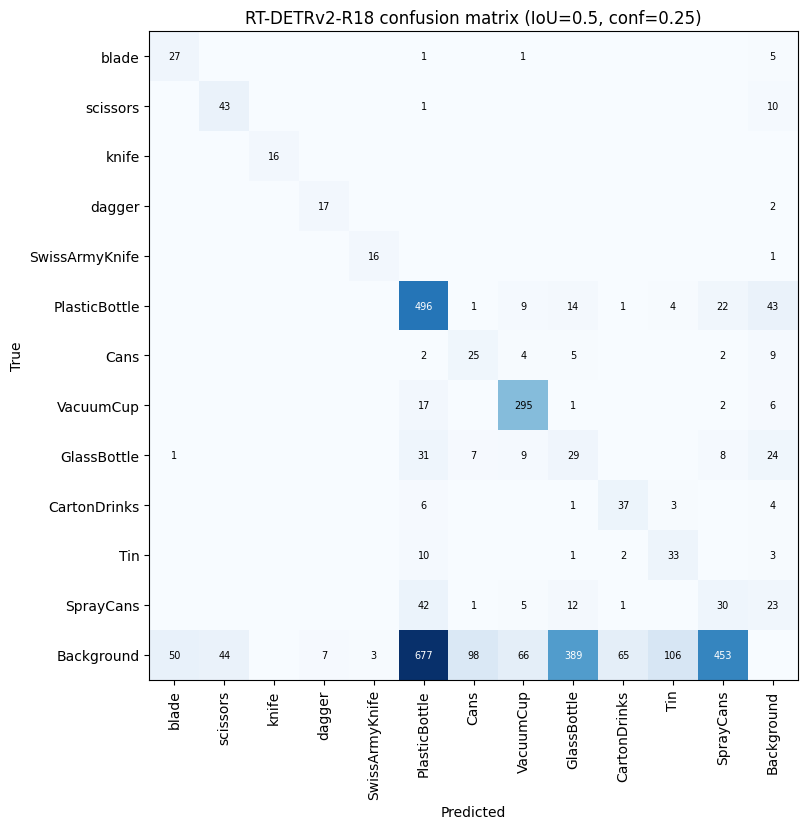

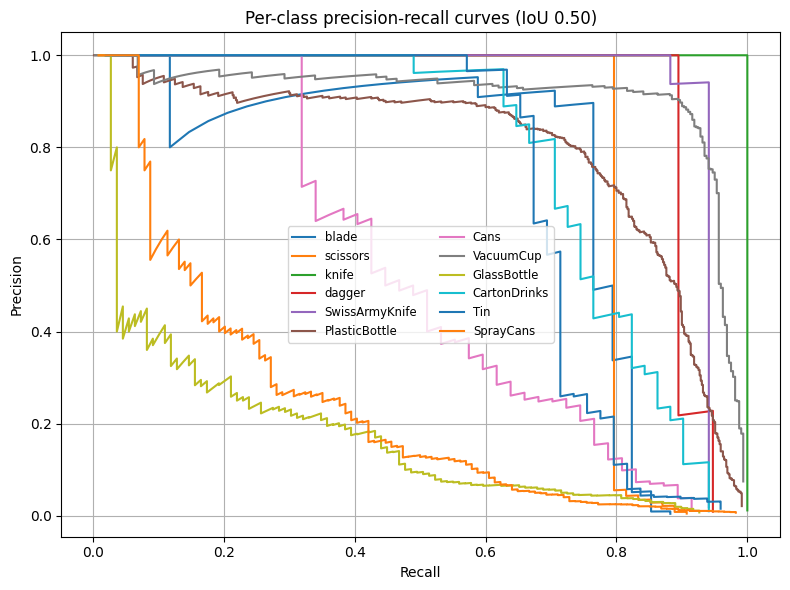

In [11]:
from collections import defaultdict
import matplotlib.pyplot as plt

CONF_THRESHOLD, IOU_THRESHOLD = 0.25, 0.50
gt = json.load(open(GT_JSON))
preds_all = json.load(open(PRED_JSON))
cat_ids = [c["id"] for c in gt["categories"]]
cat_to_idx = {cid: i for i, cid in enumerate(cat_ids)}
n_cls, bg = len(cat_ids), len(cat_ids)

gt_by_img = defaultdict(list)
for a in gt["annotations"]:
    gt_by_img[a["image_id"]].append(a)
pred_by_img = defaultdict(list)
for p in preds_all:
    pred_by_img[p["image_id"]].append(p)
for lst in pred_by_img.values():
    lst.sort(key=lambda d: -d["score"])

def iou_xywh(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    iw = max(0.0, min(ax + aw, bx + bw) - max(ax, bx)); ih = max(0.0, min(ay + ah, by + bh) - max(ay, by))
    inter = iw * ih; union = aw * ah + bw * bh - inter
    return inter / union if union > 0 else 0.0

cm = np.zeros((n_cls + 1, n_cls + 1), dtype=int)
tp = np.zeros(n_cls, int); fp = np.zeros(n_cls, int); fn = np.zeros(n_cls, int)
tp_ious = []
for image_id in set(gt_by_img) | set(pred_by_img):
    gts = gt_by_img[image_id]
    dets = [d for d in pred_by_img[image_id] if d["score"] >= CONF_THRESHOLD]
    matched = set()
    for d in dets:
        dcls = cat_to_idx[d["category_id"]]
        best_iou, best_j = 0.0, None
        for j, g in enumerate(gts):
            if j in matched: continue
            v = iou_xywh(d["bbox"], g["bbox"])
            if v > best_iou: best_iou, best_j = v, j
        if best_j is not None and best_iou >= IOU_THRESHOLD:
            matched.add(best_j); gcls = cat_to_idx[gts[best_j]["category_id"]]
            cm[gcls, dcls] += 1
            if gcls == dcls: tp[dcls] += 1; tp_ious.append(best_iou)
            else: fp[dcls] += 1; fn[gcls] += 1
        else:
            cm[bg, dcls] += 1; fp[dcls] += 1
    for j, g in enumerate(gts):
        if j not in matched:
            gcls = cat_to_idx[g["category_id"]]; cm[gcls, bg] += 1; fn[gcls] += 1

P = tp / np.maximum(tp + fp, 1); R = tp / np.maximum(tp + fn, 1)
F1 = 2 * P * R / np.maximum(P + R, 1e-12)
metric_df = pd.DataFrame({"Class": class_names, "Precision": P, "Recall": R, "F1-score": F1, "TP": tp, "FP": fp, "FN": fn})
display(metric_df.round(4))
has_gt = (tp + fn) > 0                      # average only over classes that exist in the test set
P_macro, R_macro, F_macro = P[has_gt].mean(), R[has_gt].mean(), F1[has_gt].mean()
P_micro = tp.sum() / max(tp.sum() + fp.sum(), 1); R_micro = tp.sum() / max(tp.sum() + fn.sum(), 1)
F_micro = 2 * P_micro * R_micro / max(P_micro + R_micro, 1e-12)
MEAN_IOU = float(np.mean(tp_ious)) if tp_ious else 0.0
print(f"conf>={CONF_THRESHOLD}, IoU>={IOU_THRESHOLD} | macro P/R/F1 = {P_macro:.4f}/{R_macro:.4f}/{F_macro:.4f} | "
      f"micro P/R/F1 = {P_micro:.4f}/{R_micro:.4f}/{F_micro:.4f} | mean IoU of TPs = {MEAN_IOU:.4f}")

# ---- confusion matrix ----
labels = class_names + ["Background"]
fig, ax = plt.subplots(figsize=(max(9, n_cls * 0.8), max(8, n_cls * 0.7)))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n_cls + 1)); ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(n_cls + 1)); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
thr = cm.max() / 2 if cm.max() else 1
for i in range(n_cls + 1):
    for j in range(n_cls + 1):
        if cm[i, j]: ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                             color="white" if cm[i, j] > thr else "black")
ax.set_title(f"RT-DETRv2-R18 confusion matrix (IoU={IOU_THRESHOLD}, conf={CONF_THRESHOLD})")
plt.tight_layout(); plt.savefig(WORK / "confusion_matrix.png", dpi=150); plt.show()

# ---- per-class PR curves (all detections, score-ranked) ----
by_cls_img = defaultdict(lambda: defaultdict(list))
for p in preds_all:
    by_cls_img[p["category_id"]][p["image_id"]].append(p)
gt_cls_img = defaultdict(lambda: defaultdict(list))
for a in gt["annotations"]:
    gt_cls_img[a["category_id"]][a["image_id"]].append(a)
fig, ax = plt.subplots(figsize=(8, 6))
for k, cid in enumerate(cat_ids):
    n_gt = sum(len(v) for v in gt_cls_img[cid].values())
    scores, flags = [], []
    for image_id, dets in by_cls_img[cid].items():
        gts = gt_cls_img[cid].get(image_id, [])
        used = set()
        for d in sorted(dets, key=lambda x: -x["score"]):
            best_iou, best_j = 0.0, None
            for j, g in enumerate(gts):
                if j in used: continue
                v = iou_xywh(d["bbox"], g["bbox"])
                if v > best_iou: best_iou, best_j = v, j
            ok = best_j is not None and best_iou >= IOU_THRESHOLD
            if ok: used.add(best_j)
            scores.append(d["score"]); flags.append(int(ok))
    if scores and n_gt:
        order = np.argsort(-np.asarray(scores)); f = np.asarray(flags)[order]
        ctp = np.cumsum(f); cfp = np.cumsum(1 - f)
        ax.plot(ctp / n_gt, ctp / np.maximum(ctp + cfp, 1), label=class_names[k])
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Per-class precision-recall curves (IoU 0.50)")
ax.grid(True); ax.legend(fontsize="small", ncol=2); plt.tight_layout()
plt.savefig(WORK / "pr_curves.png", dpi=150); plt.show()

## 11. Training curves
The RT-DETR repo does not compute a validation *loss*. Convergence is shown with the training loss and the validation mAP per epoch (the validation mAP is what `best.pth` and early stopping use).

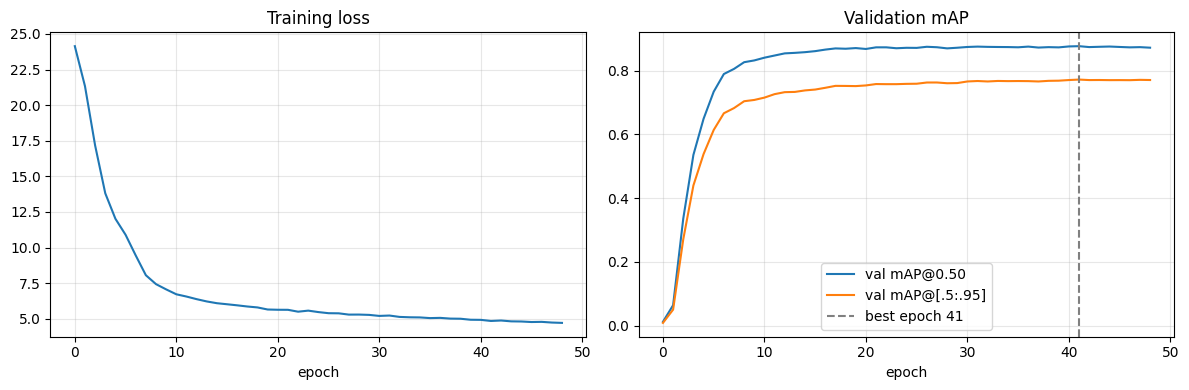

In [12]:
rows = [json.loads(l) for l in open(OUT / "log.txt")]
ep = [r["epoch"] for r in rows]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, [r["train_loss"] for r in rows]); axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch")
axes[0].grid(alpha=.3)
axes[1].plot(ep, [r["test_coco_eval_bbox"][1] for r in rows], label="val mAP@0.50")
axes[1].plot(ep, [r["test_coco_eval_bbox"][0] for r in rows], label="val mAP@[.5:.95]")
axes[1].axvline(best_ep, color="gray", ls="--", label=f"best epoch {best_ep}")
axes[1].set_title("Validation mAP"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(WORK / "training_curves.png", dpi=150); plt.show()

## 12. Sample predictions (6 test images)

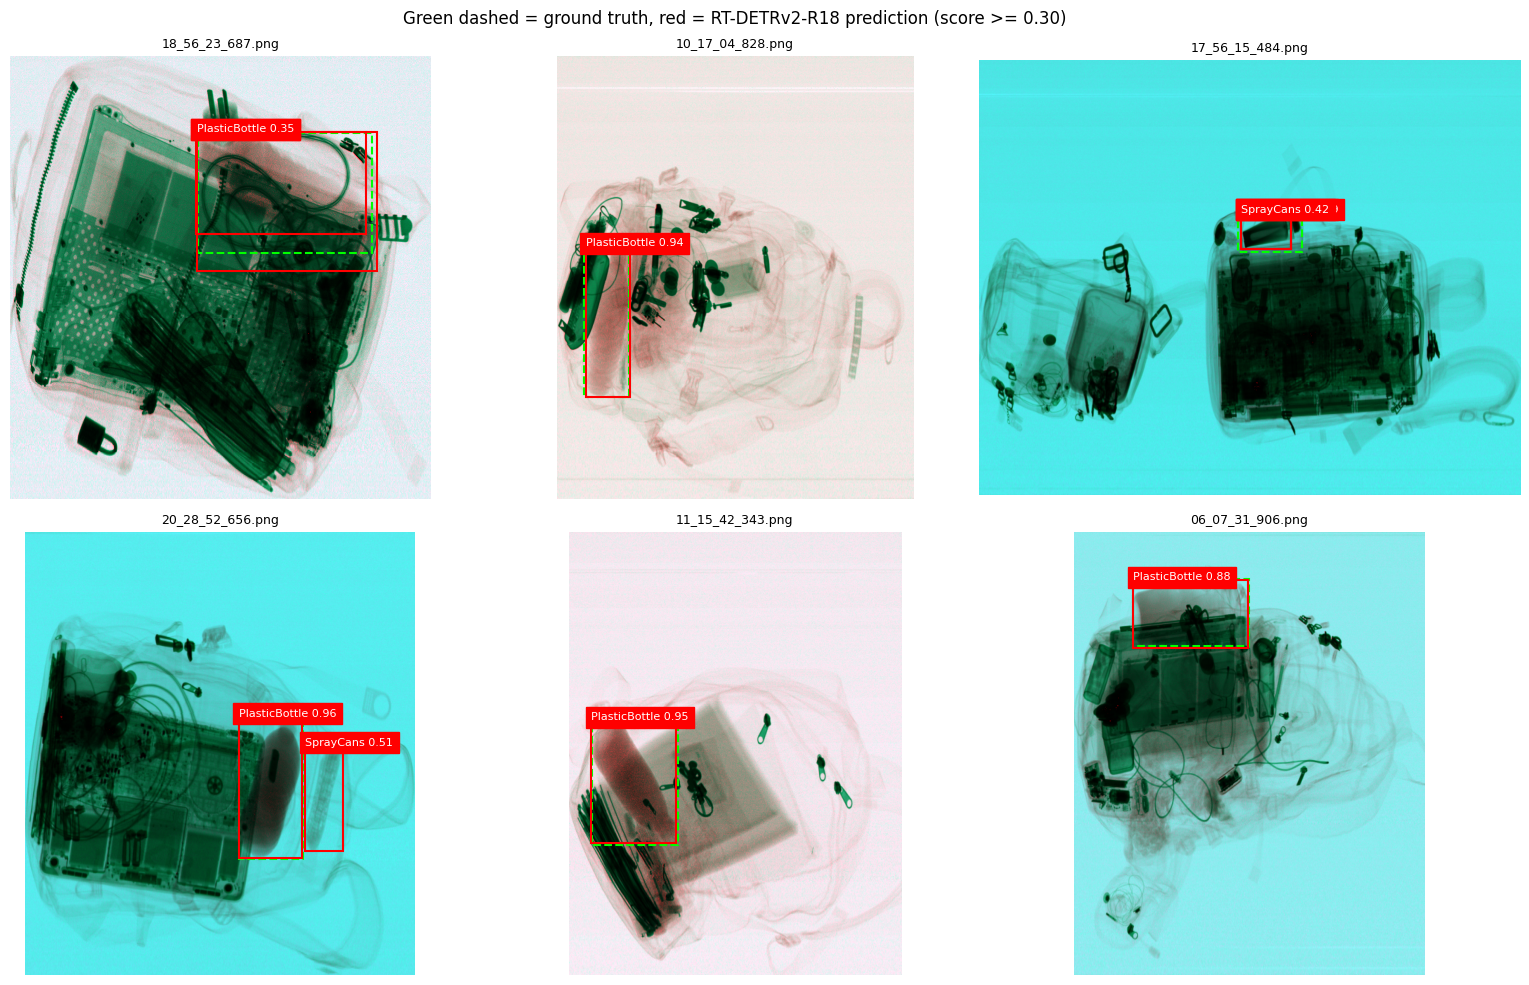

In [13]:
import matplotlib.patches as patches
img_info = {im["id"]: im for im in gt["images"]}
pick = random.Random(SEED).sample(sorted(img_info), 6)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, image_id in zip(axes.ravel(), pick):
    info = img_info[image_id]
    ax.imshow(Image.open(DATASET_ROOT / "images" / "test" / info["file_name"]).convert("RGB")); ax.axis("off")
    for g in gt_by_img[image_id]:
        x, y, w, h = g["bbox"]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="lime", lw=1.5, ls="--"))
    for d in pred_by_img[image_id]:
        if d["score"] < 0.30: continue
        x, y, w, h = d["bbox"]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="red", lw=1.5))
        ax.text(x, y, f"{class_names[d['category_id'] - 1]} {d['score']:.2f}", color="white", fontsize=8, backgroundcolor="red")
    ax.set_title(info["file_name"], fontsize=9)
plt.suptitle("Green dashed = ground truth, red = RT-DETRv2-R18 prediction (score >= 0.30)")
plt.tight_layout(); plt.savefig(WORK / "sample_predictions.png", dpi=150); plt.show()

## 13. Results row for your comparison table

In [14]:
summary = pd.DataFrame([{
    "Model": "RT-DETRv2-R18 (COCO-pretrained, fine-tuned)",
    "Params (M)": round(N_PARAMS / 1e6, 2), "GFLOPs": round(GFLOPS, 1),
    "Precision (macro)": round(P_macro, 4), "Recall (macro)": round(R_macro, 4), "F1 (macro)": round(F_macro, 4),
    "mAP@50": round(MAP50, 4), "mAP@50-95": round(MAP50_95, 4),
    "Mean IoU (TP)": round(MEAN_IOU, 4), "ms/img": round(MS_PER_IMG, 1), "FPS": round(FPS, 1),
    "Epochs run": len(rows), "Best epoch": best_ep}])
display(summary.T)
summary.to_csv(WORK / "rtdetr_results.csv", index=False)
per_class = metric_df.merge(per_class_ap, on="Class"); per_class.to_csv(WORK / "rtdetr_per_class.csv", index=False)
print(f"Precision/recall/F1: conf >= {CONF_THRESHOLD}, IoU >= {IOU_THRESHOLD}, class-averaged "
      f"(micro: P={P_micro:.4f} R={R_micro:.4f} F1={F_micro:.4f})")

,0
Model,"RT-DETRv2-R18 (COCO-pretrained, fine-tuned)"
Params (M),21.87
GFLOPs,60.2
Precision (macro),0.4519
Recall (macro),0.7205
F1 (macro),0.535
mAP@50,0.7118
mAP@50-95,0.6058
Mean IoU (TP),0.9154
ms/img,22.2


Precision/recall/F1: conf >= 0.25, IoU >= 0.5, class-averaged (micro: P=0.3275 R=0.7488 F1=0.4557)


## 14. Package deliverables

In [15]:
from IPython.display import FileLink, display
stage = WORK / "RTDETRv2_R18_deliverables"
if stage.exists(): shutil.rmtree(stage)
stage.mkdir()
for p in [BEST, OUT / "log.txt", TEST_LOG, PRED_JSON, CONFIG_PATH, TEST_CONFIG_PATH,
          WORK / "rtdetr_results.csv", WORK / "rtdetr_per_class.csv", WORK / "confusion_matrix.png",
          WORK / "pr_curves.png", WORK / "training_curves.png", WORK / "sample_predictions.png"]:
    if Path(p).exists(): shutil.copy(p, stage)
archive = shutil.make_archive(str(WORK / "RTDETRv2_R18_deliverables"), "zip", root_dir=stage)
print("Created:", archive)
display(FileLink(archive))

Created: /kaggle/working/RTDETRv2_R18_deliverables.zip


/kaggle/working/RTDETRv2_R18_deliverables.zip